In [1]:
import torch

In [2]:
from sklearn.datasets import make_circles
X,y=make_circles(n_samples=10000,noise=0.03,random_state=42)
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)
type(X_train)

numpy.ndarray

In [3]:
len(X_test)

2000

In [4]:
X_train

array([[-0.37079765,  0.90171924],
       [ 0.81409428,  0.1282455 ],
       [-0.0347326 ,  0.79141606],
       ...,
       [ 0.62623966,  0.41884778],
       [ 0.57096155,  0.8364869 ],
       [-0.83767941,  0.24247291]])

In [8]:
# X_train=torch.tensor(X_train)
X_test=torch.tensor(X_test)
y_train=torch.tensor(y_train)
y_test=torch.tensor(y_test)

In [14]:
# X_train=X_train.type(torch.float32)
X_test=X_test.type(torch.float32)
y_train=y_train.type(torch.float32)
y_test=y_test.type(torch.float32)

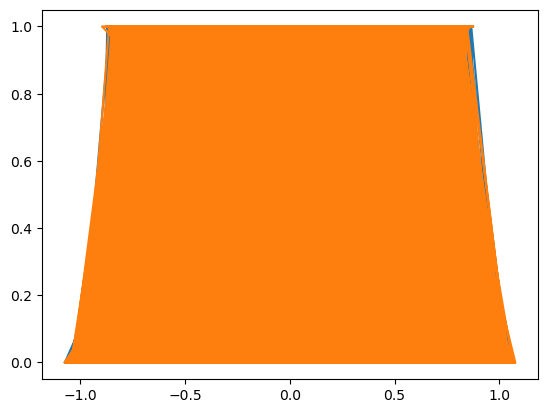

In [16]:
import matplotlib.pyplot as plt
plt.plot(X_train,y_train)

In [15]:
X_train.shape

torch.Size([8000, 2])

In [24]:
y_test.shapeloss_test=model

torch.Size([2000])

In [17]:
import torch.nn as nn


In [20]:
class classificationalmodeltanh(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.clflayers=nn.Sequential(
        nn.Linear(in_features=2,out_features=8),
        nn.Tanh(),
        nn.Linear(in_features=8,out_features=8),
        nn.Tanh(),
        nn.Linear(in_features=8,out_features=8),
        nn.Sigmoid(),
        nn.Linear(in_features=8,out_features=1))
    def forward(self,x):
        return self.clflayers(x)
    
        

In [21]:
model=classificationalmodeltanh()

In [22]:
model.state_dict()

OrderedDict([('clflayers.0.weight',
              tensor([[-0.0324, -0.3843],
                      [-0.2108, -0.1475],
                      [ 0.5584, -0.4431],
                      [-0.1709,  0.3179],
                      [ 0.1559,  0.6284],
                      [-0.1494,  0.3810],
                      [ 0.4715,  0.2857],
                      [-0.0863,  0.3077]])),
             ('clflayers.0.bias',
              tensor([-0.1844, -0.4550,  0.3449, -0.2255, -0.1579, -0.0291,  0.4170,  0.3996])),
             ('clflayers.2.weight',
              tensor([[-0.2723, -0.1576,  0.0518,  0.2166, -0.2046,  0.1066, -0.0615,  0.0304],
                      [-0.1859,  0.1856, -0.0615,  0.1685,  0.0199,  0.1976, -0.3522,  0.0521],
                      [ 0.3081,  0.2330, -0.2247, -0.3335, -0.1165, -0.1826,  0.2989, -0.0681],
                      [-0.0387,  0.2025,  0.1839, -0.2505, -0.1400,  0.0671, -0.0190, -0.3325],
                      [-0.0406,  0.0417, -0.2251,  0.1106,  0.0521,  0.205

In [23]:
loss_Fun=nn.BCEWithLogitsLoss()
optimizer=torch.optim.Adam(lr=0.1,params=model.parameters())

In [25]:
epoch=500
for epoch in range(epoch):
    model.train()
    y_train_pred=model(X_train)
    y_train_pred=y_train_pred.squeeze(dim=1)
    loss_train=loss_Fun(y_train_pred,y_train)
    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()
    
    model.eval()
    with torch.inference_mode():
        y_test_pred=model(X_test)
        y_test_pred=y_test_pred.squeeze(dim=1)
        loss_test=loss_Fun(y_test_pred,y_test)
        
    if epoch% 10 ==0 :
        print(f'epoch is -> {epoch} , train loss is {loss_train.item()} , test loss is -> {loss_test.item()}')

epoch is -> 0 , train loss is 0.70500648021698 , test loss is -> 0.7115838527679443
epoch is -> 10 , train loss is 0.6933979392051697 , test loss is -> 0.6924664378166199
epoch is -> 20 , train loss is 0.6890764236450195 , test loss is -> 0.6880059838294983
epoch is -> 30 , train loss is 0.639839768409729 , test loss is -> 0.6292022466659546
epoch is -> 40 , train loss is 0.4724057912826538 , test loss is -> 0.39221274852752686
epoch is -> 50 , train loss is 0.2963508069515228 , test loss is -> 0.2508566081523895
epoch is -> 60 , train loss is 0.13006064295768738 , test loss is -> 0.15653285384178162
epoch is -> 70 , train loss is 0.05430195480585098 , test loss is -> 0.05131220445036888
epoch is -> 80 , train loss is 0.02632356807589531 , test loss is -> 0.021150898188352585
epoch is -> 90 , train loss is 0.014782716520130634 , test loss is -> 0.01465670671314001
epoch is -> 100 , train loss is 0.010868051089346409 , test loss is -> 0.01048770546913147
epoch is -> 110 , train loss is 

In [26]:
torch.save(model,'/home/admin1/Desktop/spidey dl ~ vivekkali/makecirclesmodelstatedict')

# done making a make circles model withb train loss - > 0.00083 , and test loss -> 0.0016